<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 29: VAE/GAN Sample Generation

**Category**: CO5 – Energy-Based and Generative Models  
**Objective**: Implement a Variational Autoencoder (VAE) with the reparameterization trick and sample novel images from latent space manifolds.


### Task 1: Construct and Train Variational Autoencoder (VAE)


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

# Synthesize 16x16 ring / circle images
N_img = 400
img_w = 16
X_rings = np.zeros((N_img, 1, img_w, img_w), dtype=np.float32)

y, x = np.ogrid[:img_w, :img_w]
for i in range(N_img):
    r = np.random.uniform(3.0, 6.0)
    dist = np.sqrt((x - 7.5)**2 + (y - 7.5)**2)
    mask = (dist >= r - 0.9) & (dist <= r + 0.9)
    X_rings[i, 0] = mask.astype(np.float32) + np.random.normal(0, 0.05, (img_w, img_w))

X_rings_t = torch.tensor(X_rings)

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 64),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z).view(-1, 1, 16, 16)
        return recon, mu, logvar

vae = ConvVAE(latent_dim=2)
optimizer = optim.Adam(vae.parameters(), lr=0.008)

loss_curve = []
for ep in range(50):
    optimizer.zero_grad()
    recon, mu, logvar = vae(X_rings_t)
    recon_loss = nn.functional.binary_cross_entropy(recon, torch.clamp(X_rings_t, 0, 1), reduction='sum') / N_img
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / N_img
    total_loss = recon_loss + kld
    total_loss.backward()
    optimizer.step()
    loss_curve.append(total_loss.item())

print(f"VAE Trained for 50 Epochs. Final ELBO Loss: {loss_curve[-1]:.3f}")


VAE Trained for 50 Epochs. Final ELBO Loss: 37.444


### Task 2: Generate Synthetic Visual Samples Across Latent Manifold


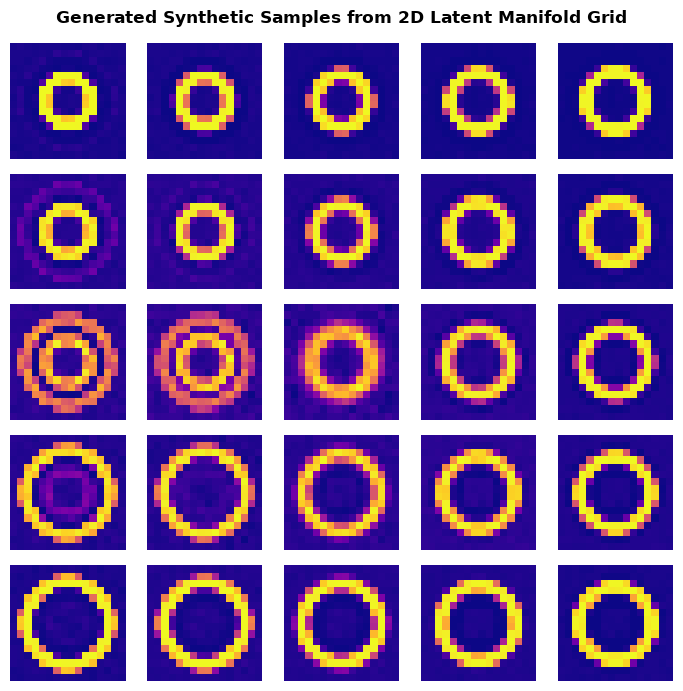

In [2]:
# Sample uniformly from standard Gaussian latent prior N(0, I)
n_grid = 5
z_grid_vals = np.linspace(-1.8, 1.8, n_grid)
fig, axes = plt.subplots(n_grid, n_grid, figsize=(7, 7))

vae.eval()
with torch.no_grad():
    for r_idx, z_y in enumerate(z_grid_vals):
        for c_idx, z_x in enumerate(z_grid_vals):
            z_sample = torch.tensor([[z_x, z_y]], dtype=torch.float32)
            gen_img = vae.decoder(z_sample).view(16, 16).numpy()
            axes[r_idx, c_idx].imshow(gen_img, cmap='plasma')
            axes[r_idx, c_idx].axis('off')

plt.suptitle("Generated Synthetic Samples from 2D Latent Manifold Grid", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
